# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/labs/lab01_regression.ipynb)

# BME i9400 — Lab 1
## A Regression Baseline for Body Fat

**Fall 2026 · Released Monday, October 5 · Notebook due Tuesday, October 14, 11:59 AM EST · Defense quiz Wednesday, October 14, in class**

In this lab you carry out a complete regression study on your own: prepare a dataset, fit and
regularise a linear model, choose between models on validation data, evaluate the choice once on a
test set, and report the result. The methods are those of Meetings 6 and 7. The dataset is new.

**How the lab is assessed.** The lab component of the course is 20% of the grade, over three labs.
Within a lab, the in-class defense quiz counts 70% and the submitted notebook 30%.

- **The notebook** is graded on whether it runs from top to bottom without error, whether every task
  is complete and correct, and on the quality of the report in section 8.
- **The defense quiz** is a ten-minute written quiz at the start of Meeting 10, taken closed-book: no
laptop, no notes, no AI tools. It asks you to explain and justify what is in *your* notebook: why a step was taken, what a
  number means, what would have happened otherwise. Section 9 describes it.

**Generative AI is permitted and expected** on the notebook. Use it as you would in practice: to
write code, to debug, to check your understanding. You are responsible for every line you submit,
and the defense tests whether you can account for it without assistance. Record how you used AI in
section 9.

**Work individually.** Discussion of approach is encouraged; code and text must be your own.

---
## 1 — The question and the data

Body fat percentage is a measure of health that is difficult to measure directly. The reference
method in this dataset is underwater weighing: the subject is weighed in air and fully submerged,
body density is computed from the two weights, and body fat is estimated from density by Siri's
equation,

$$\text{body fat (\%)} = \frac{495}{\text{density}} - 450$$

Underwater weighing needs a tank, trained staff, and a cooperative subject. A tape measure and a
scale need none of these. The question of this lab is the question of Penrose, Nelson and Fisher
(*Medicine & Science in Sports & Exercise*, 1985): **how well can body fat be predicted from
circumference measurements, weight, height, and age?**

### The data

252 men, measured at the Human Performance Research Center, Brigham Young University; the data were
made public by Johnson, "Fitting Percentage of Body Fat to Simple Body Measurements", *Journal of
Statistics Education*, 1996, with permission for non-commercial use. The course copy is
`data/bodyfat.csv`, one row per man.

| Column | Meaning | Units |
|---|---|---|
| `case` | identifier, 1 to 252 | |
| `body_fat_pct` | **the target**: body fat from Siri's equation | % |
| `density` | body density from underwater weighing | g/cm³ |
| `age` | age | years |
| `weight_lb` | weight | pounds |
| `height_in` | height | inches |
| `bmi` | body mass index, computed from weight and height | kg/m² |
| `neck`, `chest`, `abdomen`, `hip`, `thigh`, `knee`, `ankle`, `biceps`, `forearm`, `wrist` | circumferences | cm |

The documentation that accompanies the data states that it is "as received" and contains "a few
errors". Finding them is part of section 2.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL  = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/bodyfat.csv"
data = pd.read_csv(URL)

circumferences = ["neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps", "forearm", "wrist"]
measurements   = ["age", "weight_lb", "height_in", "bmi"] + circumferences      # everything a clinic can measure
target         = "body_fat_pct"

print(f"{len(data)} men, {data.shape[1]} columns")
data.describe().T[["mean", "std", "min", "max"]].round(2)

252 men, 17 columns


,mean,std,min,max
case,126.50,72.89,1.0,252.00
body_fat_pct,19.15,8.37,0.0,47.50
density,1.06,0.02,1.0,1.11
age,44.88,12.60,22.0,81.00
weight_lb,178.92,29.39,118.5,363.15
height_in,70.15,3.66,29.5,77.75
bmi,25.44,3.65,18.1,48.90
neck,37.99,2.43,31.1,51.20
chest,100.82,8.43,79.3,136.20
abdomen,92.56,10.78,69.4,148.10


---
## 2 — Data readiness

Before any model is fitted, two questions from Meeting 1: are the values plausible, and is every
column one that would be available when the model is used?

### 2.1 Implausible values

The summary table above already shows at least two impossible values. Write code that finds every
row in which **height is below 50 inches** or **body fat is at most 0%**, and look at those rows in
full. Then decide what to do with each one — correct it, remove it, or keep it — and state the
decision and the reason in the answer cell. A decision without a reason receives no credit.

> Removing a row because it is inconvenient is not a reason. A value that is physically impossible,
> or that the documentation identifies as a recording error, is. The `bmi` column, which was
> computed from weight and height before the error was made, is evidence about what the height
> should have been.

In [12]:
# --- TODO: find the implausible rows ---
suspect = data[(data["height_in"]<50) | (data["body_fat_pct"] <= 0)]          # a DataFrame: the rows with height_in < 50 or body_fat_pct <= 0

assert suspect is not None, "Fill in suspect."
assert len(suspect) >= 2 and ((suspect["height_in"] < 50) | (suspect["body_fat_pct"] <= 0)).all(), \
    "suspect should hold exactly the rows that meet one of the two conditions."
suspect

,case,body_fat_pct,density,age,weight_lb,height_in,bmi,neck,chest,abdomen,hip,thigh,knee,ankle,biceps,forearm,wrist
41,42,32.9,1.0250,44,205.0,29.5,29.9,36.6,106.0,104.3,115.5,70.6,42.5,23.7,33.6,28.7,17.4
181,182,0.0,1.1089,40,118.5,68.0,18.1,33.8,79.3,69.4,85.0,47.2,33.5,20.2,27.7,24.6,16.5


In [13]:
# --- TODO: apply your decisions, producing the DataFrame `clean` ---
# For a row you correct, change the value; for a row you remove, drop it; for a row you keep, do nothing.
clean = data.copy()

# Decision 1 -- CORRECT the impossible height (29.5 in). bmi was computed before the error was made, so it
# lets us recover the height: bmi = weight_kg / height_m^2  =>  height_m = sqrt(weight_kg / bmi).
bad_height = clean["height_in"] < 50
w_kg       = clean.loc[bad_height, "weight_lb"] * 0.45359237
h_in       = np.sqrt(w_kg / clean.loc[bad_height, "bmi"]) / 0.0254
print("height implied by weight and bmi:", h_in.round(2).tolist(), "inches")
clean.loc[bad_height, "height_in"] = (h_in * 4).round() / 4          # heights are recorded to 1/4 inch

# Decision 2 -- REMOVE the row with 0% body fat. Nothing in the row tells us the true value
# (density 1.1089 is itself implausible, and Siri's equation gives a negative body fat from it).
clean = clean[clean["body_fat_pct"] > 0].reset_index(drop=True)


assert clean is not None, "Produce the DataFrame clean."
assert set(clean.columns) == set(data.columns) and len(clean) <= len(data), "clean should keep the same columns."
print(f"{len(clean)} men remain after your decisions ({len(data) - len(clean)} removed)")

height implied by weight and bmi: [69.43] inches
251 men remain after your decisions (1 removed)


**Answer 2.1** — For Case 42, I noticed the height to be impossible (29.5in) and decided to correct the height by using the formula bmi = weight_kg / height m^2. I rearranged the formula to solve for height. When I ran the code, I received the height of 69.43 inches, which is more realistic. For Case 182, I decided to remove since the body fat percentage is zero, and the recorded density is well out of range. There is no way to correct the true value of the density and using Siri's equation, the calculated body fat percentage was actually -3.6%, which is impossible.

### 2.2 The column that must not be used

One column in this file is not a measurement a clinic could take with a scale and a tape measure,
and it is related to the target by a formula. Identify it, and demonstrate what happens when it is
included as a feature: fit a least squares model on all 14 measurements with and without that
column, on the full cleaned dataset, and compare the two values of $R^2$.

> Using a feature that is computed from the target, or that would only be known once the target is
> known, is called **target leakage**. The resulting model looks excellent and is useless, because
> the feature will not exist when the model is applied to a new person. Leakage of this kind is one
> of the most common ways in which a published model fails in practice (Meeting 1).

In [14]:
from sklearn.linear_model import LinearRegression

leaky_column = "density"          # TODO: the name of the column

# --- TODO: fit on the 14 measurements plus the leaky column, and on the 14 measurements alone ---
m_with    = LinearRegression().fit(clean[measurements + [leaky_column]], clean[target])
m_without = LinearRegression().fit(clean[measurements],                  clean[target])
r2_with    = m_with.score(clean[measurements + [leaky_column]], clean[target])      # R^2 on the data used for fitting, with the leaky column
r2_without = m_without.score(clean[measurements],               clean[target])      # ... without it


assert leaky_column is not None, "Fill in leaky_column."
assert leaky_column in clean.columns and leaky_column not in measurements + ["case", target], \
    "Name the column that is neither a clinic measurement, nor the identifier, nor the target."
assert r2_with is not None and r2_without is not None, "Fit both models."
print(f"R^2 with {leaky_column}: {r2_with:.3f}     without: {r2_without:.3f}")
assert r2_with > 0.95 > r2_without, "Including the leaky column should make the fit nearly perfect."

R^2 with density: 0.979     without: 0.745


**Answer 2.2** —
 The leaky column is density. The formula that is used to calculate the target is Siri's equation, body fat(%) = 495 / density - 450. Since density data is given, the least squares on the full cleaned dataset reaches R^2 = 0.979. With only the 14 clinic measurements, it is 0.745. A model that used density would fail in a clinic since density comes from underwater weighing. The model is meant to replace the procedure, which means it has to be able to predict the correct body fat percentage with only the measurements from the clinic.  

---
## 3 — Splitting the data

Three sets are needed: a **training set** to fit weights, a **validation set** to choose between
models and to choose $\lambda$, and a **test set** that is touched exactly once, in section 7.

> The training and validation sets together are called the **development set**: everything that may
> be used while the model is being built.

The test split is fixed below so that every student's test set is the same 63 men. The validation
split inside the development set is yours to make; use a fixed `random_state` so that your notebook
is reproducible.

In [15]:
from sklearn.model_selection import train_test_split

X_all = clean[measurements].values
y_all = clean[target].values

# Done for you: the test set, 25% of the men, identical for every student.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=9400)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=0)

assert X_train is not None, "Make the validation split."
assert len(X_train) + len(X_val) == len(X_dev) and len(X_val) >= 0.2 * len(X_dev), \
    "Validation should be about a quarter of the development set."
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}")
print(f"body fat in the training set: mean {y_train.mean():.1f}%, standard deviation {y_train.std(ddof=1):.1f}%")

training 141   validation 47   test 63
body fat in the training set: mean 19.5%, standard deviation 8.6%


---
## 4 — The least squares baseline

Fit ordinary least squares on all 14 measurements, by the normal equations or with
`LinearRegression` (if you use both, verify that they agree). Report:

- RMSE and $R^2$ on the training and validation sets, in units of body fat percentage points
- the RMSE of the model that predicts the training mean for everyone, which any model must beat
- the fitted weights, each with its units (percentage points of body fat per year, per pound, per
  inch, per kg/m², per centimetre)
- a plot of the residuals against the fitted values on the training set

Then read the weights. Several have signs opposite to the correlation of their feature with body
fat. Compute the correlation matrix of the 14 measurements and use it to explain why, in the answer
cell (Meeting 7, section 4).

predict-the-mean baseline, validation RMSE: 7.11 percentage points
least squares:  training RMSE 3.81  R^2 0.801   |   validation RMSE 4.63  R^2 0.564
normal equations agree with LinearRegression: True
intercept: -138.55 percentage points


,weight,units,corr with body fat,sign opposite?
age,0.050,pp per year,0.264,False
weight_lb,-0.421,pp per pound,0.637,True
height_in,1.277,pp per inch,0.005,False
bmi,1.549,pp per kg/m^2,0.733,False
neck,-0.036,pp per cm,0.533,True
chest,-0.012,pp per cm,0.737,True
abdomen,1.076,pp per cm,0.828,False
hip,-0.193,pp per cm,0.643,True
thigh,0.384,pp per cm,0.610,False
knee,0.128,pp per cm,0.549,False


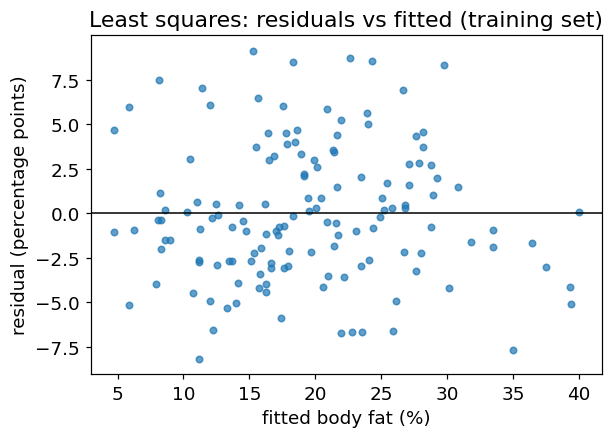

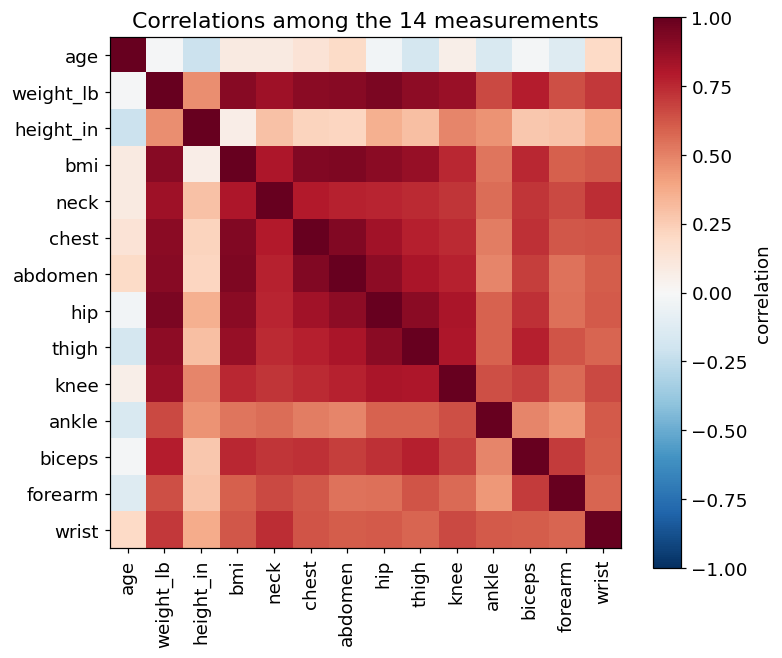

Variance inflation factors (how much collinearity inflates each weight's variance):
weight_lb    194.0
bmi          152.8
height_in     30.2
abdomen       14.9
hip           14.4
chest         12.5
thigh         10.7
neck           5.2
knee           5.1
biceps         3.5
wrist          3.2
forearm        2.6
age            2.3
ankle          2.3

weight_lb vs bmi: r = 0.91;  weight_lb vs abdomen: r = 0.91;  weight_lb vs hip: r = 0.94


In [16]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def r_squared(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_true.mean())**2)

# --- TODO: fit least squares on all 14 measurements ---
ols            = LinearRegression().fit(X_train, y_train)          # the fitted model, or the weight vector from the normal equations
pred_train_ols = ols.predict(X_train)
pred_val_ols   = ols.predict(X_val)

assert pred_train_ols is not None and pred_val_ols is not None, "Fit the model and predict both sets."
baseline_rmse = rmse(y_val, np.full_like(y_val, y_train.mean(), dtype=float))
print(f"predict-the-mean baseline, validation RMSE: {baseline_rmse:.2f} percentage points")
print(f"least squares:  training RMSE {rmse(y_train, pred_train_ols):.2f}  R^2 {r_squared(y_train, pred_train_ols):.3f}"
      f"   |   validation RMSE {rmse(y_val, pred_val_ols):.2f}  R^2 {r_squared(y_val, pred_val_ols):.3f}")
assert rmse(y_val, pred_val_ols) < baseline_rmse, "The model should beat the mean."

# --- TODO: print each weight with its units; plot residuals against fitted values; show the correlations ---

# (a) Cross-check against the normal equations  w = (A^T A)^{-1} A^T y,  A = [1, X]
A     = np.column_stack([np.ones(len(X_train)), X_train])
w_ne  = np.linalg.lstsq(A, y_train, rcond=None)[0]               # numerically stable way to solve the normal equations
print("normal equations agree with LinearRegression:",
      np.allclose(w_ne[0], ols.intercept_) and np.allclose(w_ne[1:], ols.coef_))

# (b) Weights with units. "pp" = percentage points of body fat.
units = {"age": "pp per year", "weight_lb": "pp per pound", "height_in": "pp per inch", "bmi": "pp per kg/m^2"}
units.update({c: "pp per cm" for c in circumferences})
train_df  = pd.DataFrame(X_train, columns=measurements)
corr_y    = train_df.corrwith(pd.Series(y_train))                # correlation of each feature with body fat
weight_tb = pd.DataFrame({"weight": ols.coef_, "units": pd.Series(units),
                          "corr with body fat": corr_y})
weight_tb["sign opposite?"] = np.sign(weight_tb["weight"]) != np.sign(weight_tb["corr with body fat"])
print(f"intercept: {ols.intercept_:.2f} percentage points")
display(weight_tb.round(3))

# (c) Residuals against fitted values, training set
resid_train = y_train - pred_train_ols
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(pred_train_ols, resid_train, s=18, alpha=0.7)
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("fitted body fat (%)"); ax.set_ylabel("residual (percentage points)")
ax.set_title("Least squares: residuals vs fitted (training set)")
plt.show()

# (d) The correlation matrix of the 14 measurements (training set), and variance inflation factors
corr = train_df.corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(14)); ax.set_xticklabels(measurements, rotation=90)
ax.set_yticks(range(14)); ax.set_yticklabels(measurements)
fig.colorbar(im, ax=ax, label="correlation"); ax.set_title("Correlations among the 14 measurements")
plt.show()

vif = pd.Series(np.diag(np.linalg.inv(corr.values)), index=measurements, name="VIF")   # variance inflation factors
print("Variance inflation factors (how much collinearity inflates each weight's variance):")
print(vif.round(1).sort_values(ascending=False).to_string())
print(f"\nweight_lb vs bmi: r = {corr.loc['weight_lb','bmi']:.2f};  weight_lb vs abdomen: r = {corr.loc['weight_lb','abdomen']:.2f};"
      f"  weight_lb vs hip: r = {corr.loc['weight_lb','hip']:.2f}")

**Answer 4** —
Six of the weights have an opposite sign to their feature's correlation with body fat. These include weight_lb, wrist, hip, ankle, neck, and chest. The measurements are strongly correlated with each other, and a weight is the effect holding the other features fixed, so a feature can get a negative weight to correct for its correlated partners.

---
## 5 — Ridge regression

Standardise the 14 measurements with the **training-set** mean and standard deviation, fit ridge
regression over a grid of $\lambda$ (`sklearn.linear_model.Ridge(alpha=...)`, or your own
implementation from Meeting 7), and:

- plot the validation RMSE against $\lambda$ on a logarithmic axis, and report the $\lambda$ that
  minimises it
- plot the weights against $\lambda$ (the coefficient paths), and say which weights the penalty
  shrinks first and why

> `Ridge(alpha=λ)` uses the convention of Meeting 7: a penalty on the weights, none on the intercept.

best lambda: 1.78    validation RMSE there: 4.59    (least squares: 4.63)


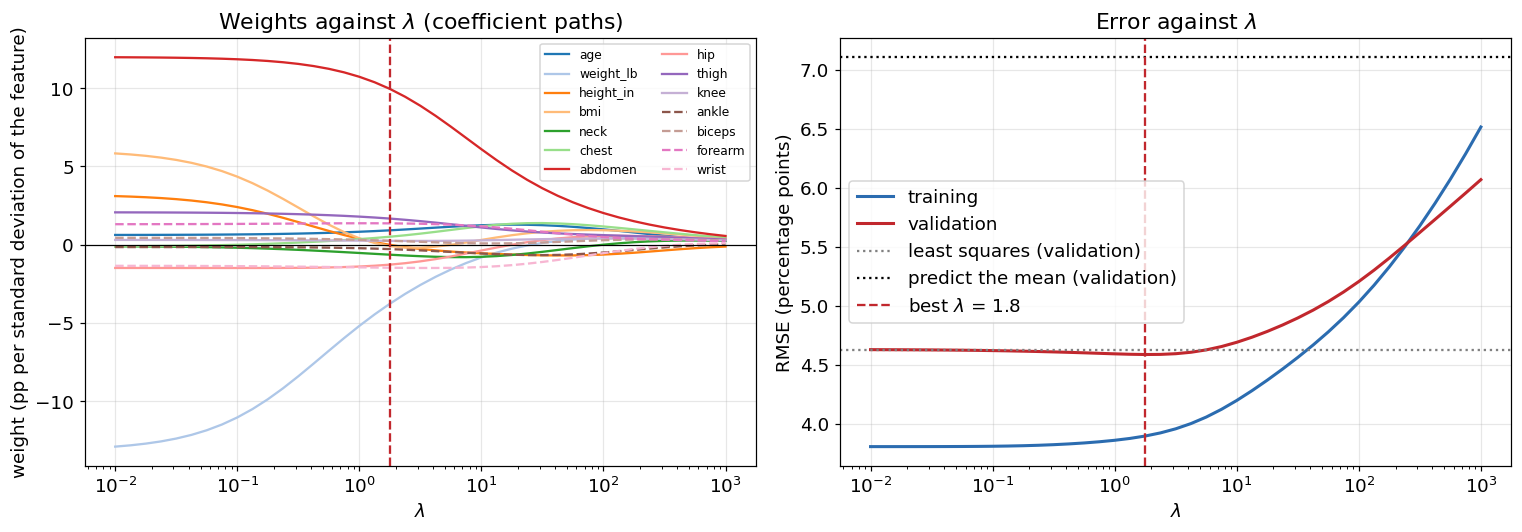

fraction of each weight kept at the best lambda (relative to lambda = 0.01):
height_in    0.00
bmi          0.01
weight_lb    0.29
biceps       0.58
thigh        0.81
knee         0.81
abdomen      0.83
hip          0.86
forearm      1.04
wrist        1.09
age          1.47
ankle        1.88
chest        5.60
neck         6.36


In [17]:
from sklearn.linear_model import Ridge

mu, sd         = X_train.mean(axis=0), X_train.std(axis=0, ddof=0)            # TODO: training-set mean and standard deviation of each measurement, shape (14,)
Z_train, Z_val = (X_train - mu) / sd, (X_val - mu) / sd                      # TODO: standardised training and validation features

# Ridge by the closed form of Meeting 7, section 5:  w = (X^T X + lambda I)^{-1} X^T y,  intercept not penalised
def design(A):
    """Place the column of ones in front of the feature matrix A."""
    return np.column_stack([np.ones(len(A)), A])

def fit_ridge(Xd, y, lam):
    """Ridge weights for the design matrix Xd (first column all ones) and penalty lam.
    The intercept is not penalised."""
    I = np.eye(Xd.shape[1])
    I[0, 0] = 0.0
    return np.linalg.solve(Xd.T @ Xd + lam * I, Xd.T @ y)

Zd_train, Zd_val = design(Z_train), design(Z_val)

# Checks, as in Meeting 7: lam = 0 is least squares (standardising does not change the predictions), and sklearn agrees
assert np.allclose(Zd_val @ fit_ridge(Zd_train, y_train, 0.0), pred_val_ols), "With lam = 0, ridge should reproduce the least squares predictions."
w_10     = fit_ridge(Zd_train, y_train, 10.0)
sk_ridge = Ridge(alpha=10.0).fit(Z_train, y_train)
assert np.allclose(w_10[1:], sk_ridge.coef_) and np.isclose(w_10[0], sk_ridge.intercept_), "Disagrees with sklearn.linear_model.Ridge."

lambdas = np.logspace(-2, 3, 41)
# --- TODO: fit Ridge for every lambda; collect the validation RMSE and the weight vectors ---
W         = np.array([fit_ridge(Zd_train, y_train, lam) for lam in lambdas])   # one row of weights per lambda (column 0 is the intercept)
train_err = np.array([rmse(y_train, Zd_train @ w) for w in W])
val_rmse  = np.array([rmse(y_val,   Zd_val   @ w) for w in W])                 # array, one entry per lambda
weights   = W[:, 1:]                                                           # array of shape (len(lambdas), 14): the 14 feature weights
best        = int(np.argmin(val_rmse))
best_lambda = lambdas[best]


assert Z_train is not None and np.allclose(Z_train.mean(axis=0), 0, atol=1e-8), "Standardise with the training statistics."
assert val_rmse is not None and len(val_rmse) == len(lambdas) and best_lambda is not None, "Fill in the sweep."
print(f"best lambda: {best_lambda:.3g}    validation RMSE there: {np.min(val_rmse):.2f}    (least squares: {rmse(y_val, pred_val_ols):.2f})")

# --- TODO: the two plots ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.tab20(np.arange(14))                                  # 14 distinct colours (the default cycle repeats after 10)
for j, name in enumerate(measurements):
    axes[0].semilogx(lambdas, weights[:, j], label=name, color=colors[j], ls="-" if j < 10 else "--")
axes[0].axhline(0, color="k", lw=0.8); axes[0].axvline(best_lambda, ls="--", color="#c1272d")
axes[0].set_xlabel("$\\lambda$"); axes[0].set_ylabel("weight (pp per standard deviation of the feature)")
axes[0].set_title("Weights against $\\lambda$ (coefficient paths)"); axes[0].legend(ncol=2, fontsize=8)

axes[1].semilogx(lambdas, train_err, lw=2, color="#2b6cb0", label="training")
axes[1].semilogx(lambdas, val_rmse,  lw=2, color="#c1272d", label="validation")
axes[1].axhline(rmse(y_val, pred_val_ols), color="gray", ls=":", label="least squares (validation)")
axes[1].axhline(baseline_rmse, color="k", ls=":", label="predict the mean (validation)")
axes[1].axvline(best_lambda, ls="--", color="#c1272d", label=f"best $\\lambda$ = {best_lambda:.2g}")
axes[1].set_xlabel("$\\lambda$"); axes[1].set_ylabel("RMSE (percentage points)")
axes[1].set_title("Error against $\\lambda$"); axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# How much of its least-squares-like value does each weight keep at the chosen lambda?
keep = pd.Series(np.abs(weights[best]) / np.abs(weights[0]), index=measurements)
print("fraction of each weight kept at the best lambda (relative to lambda = 0.01):")
print(keep.round(2).sort_values().to_string())

**Answer 5** — λ = 1.78. I standardised the features with the training-set mean and standard deviation (so the penalty treats every weight alike), fitted ridge on 41 log-spaced values of λ from 0.01 to 1000, and took the λ with the smallest validation RMSE, 4.59 pp against 4.63 pp for least squares; the curve is nearly flat up to λ ≈ 5, so the gain is small. The penalty shrinks height_in, bmi and weight_lb first because they are nearly redundant (BMI is computed from weight and height), so least squares gave them large weights that cancel, and the penalty makes large weights costly while shrinking them barely hurts the fit. Abdomen, which has signal of its own, keeps 83% of its weight.

---
## 6 — A parsimonious model

A clinic would rather take three measurements than thirteen. Choose **at most three** of the 14
measurements, fit least squares on them, and compare the validation RMSE with the full model and
with ridge. Justify the choice with evidence from your notebook — correlations with the target,
correlations among the features, the weights — not with intuition alone.

> There is no single correct answer. A choice that is defended with evidence and evaluated honestly
> is correct; a choice that happens to score well is not.

In [18]:
# --- TODO: choose up to three measurements and fit least squares on them ---
# Evidence 1: correlation of each measurement with body fat (training set) -- printed in section 4.
# Evidence 2: forward selection, scored by 10-fold cross-validation INSIDE the training set
#             (the validation set is not used to choose, so it can still evaluate the choice honestly).
from sklearn.model_selection import KFold, cross_val_score

cv         = KFold(10, shuffle=True, random_state=0)
selected   = []
for step in range(3):
    scores = {}
    for m in measurements:
        if m in selected:
            continue
        cols = [measurements.index(c) for c in selected + [m]]
        scores[m] = -cross_val_score(LinearRegression(), X_train[:, cols], y_train,
                                     cv=cv, scoring="neg_root_mean_squared_error").mean()
    best = min(scores, key=scores.get)
    selected.append(best)
    print(f"step {step + 1}: add {best:<10s} cross-validated RMSE {scores[best]:.2f}")

full_cv = -cross_val_score(LinearRegression(), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
print(f"(all 14 measurements, same cross-validation: {full_cv:.2f})")

chosen         = selected                                            # a list of 1 to 3 column names from `measurements`
cols_small     = [measurements.index(c) for c in chosen]
small          = LinearRegression().fit(X_train[:, cols_small], y_train)      # the fitted model
pred_val_small = small.predict(X_val[:, cols_small])

assert chosen is not None and 1 <= len(chosen) <= 3 and all(c in measurements for c in chosen), "Choose 1 to 3 measurements."
assert pred_val_small is not None, "Fit the model and predict the validation set."
print(f"{chosen}: validation RMSE {rmse(y_val, pred_val_small):.2f}   "
      f"(full least squares {rmse(y_val, pred_val_ols):.2f}, ridge {np.min(val_rmse):.2f}, mean {baseline_rmse:.2f})")
# The weights of the small model, with units, and the correlations that justify the choice
print("\nsmall-model weights:", {c: round(float(w), 3) for c, w in zip(chosen, small.coef_)}, " intercept", round(float(small.intercept_), 2))
print("\ncorrelations among the chosen measurements (training set):")
print(train_df[chosen].corr().round(2).to_string())
print("\ncorrelation of each chosen measurement with body fat:", corr_y[chosen].round(2).to_dict())

step 1: add abdomen    cross-validated RMSE 4.87
step 2: add weight_lb  cross-validated RMSE 4.32
step 3: add forearm    cross-validated RMSE 4.19
(all 14 measurements, same cross-validation: 4.19)
['abdomen', 'weight_lb', 'forearm']: validation RMSE 4.85   (full least squares 4.63, ridge 4.59, mean 7.11)

small-model weights: {'abdomen': 1.115, 'weight_lb': -0.215, 'forearm': 0.691}  intercept -65.43

correlations among the chosen measurements (training set):
           abdomen  weight_lb  forearm
abdomen       1.00       0.91     0.54
weight_lb     0.91       1.00     0.64
forearm       0.54       0.64     1.00

correlation of each chosen measurement with body fat: {'abdomen': 0.83, 'weight_lb': 0.64, 'forearm': 0.44}


**Answer 6** — I chose abdomen, weight_lb and forearm. Abdomen has the strongest correlation with body fat (r = 0.83), and forward selection scored by 10-fold cross-validation on the training set then added weight_lb (cross-validated RMSE 4.87 → 4.32) and forearm (→ 4.19), which matches all 14 measurements (4.19). Weight_lb helps even though it correlates 0.91 with abdomen, because the pair works as abdomen relative to body mass, so its negative weight (−0.22 pp/lb) is a correction, not an effect of weight on fat. The validation RMSE is 4.85, slightly worse than full least squares (4.63) and ridge (4.59) but far better than the mean (7.11); with only 47 validation men that gap is within noise.

---
## 7 — The test set, once

Every decision has now been made on validation data: the data cleaning, $\lambda$, and the small
model. Refit each model on the **development set** — training and validation together — with its
chosen settings (standardise with the development set's statistics for ridge), and evaluate all of
them on the test set. Report, in one table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |

and a plot of predicted against observed body fat on the test set for your preferred model. The test
set is not used again after this cell. If you change a model after seeing these numbers, the test
set is no longer a test set.

                                   model  test RMSE  test R^2
        predict the development-set mean      8.533    -0.000
          least squares, 14 measurements      5.015     0.655
                     ridge, lambda = 1.8      4.796     0.684
small model: abdomen, weight_lb, forearm      4.899     0.670


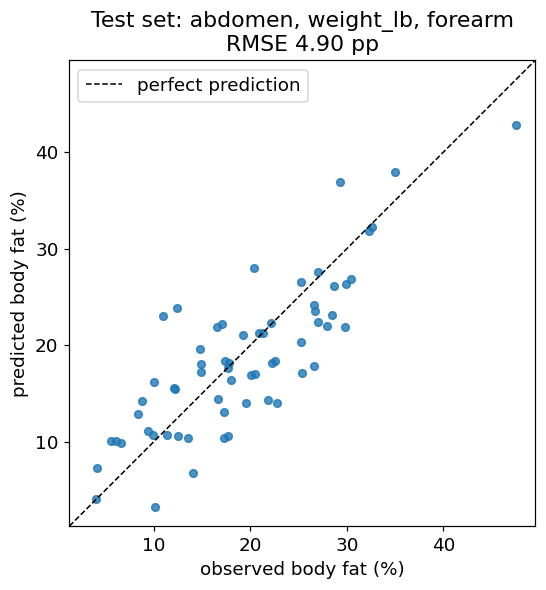

In [19]:
# --- TODO: refit each model on the development set and evaluate on the test set ---
# Standardise with the DEVELOPMENT set's statistics (Meeting 7, section 4). Then every model is one call to
# fit_ridge from section 5: lam = 0 is least squares, lam = best_lambda is ridge.
mu_dev, sd_dev  = X_dev.mean(axis=0), X_dev.std(axis=0, ddof=1)
Zd_dev, Zd_test = design((X_dev - mu_dev) / sd_dev), design((X_test - mu_dev) / sd_dev)

all_cols   = list(range(15))                                           # the intercept column and the 14 measurements
small_cols = [0] + [measurements.index(c) + 1 for c in chosen]        # the intercept column and the measurements of section 6

def test_predictions(cols, lam):
    """Refit on the development set (columns cols, penalty lam) and predict the test set."""
    w = fit_ridge(Zd_dev[:, cols], y_dev, lam)
    return Zd_test[:, cols] @ w

small_name  = f"small model: {', '.join(chosen)}"
predictions = {"predict the development-set mean": np.full_like(y_test, y_dev.mean(), dtype=float),
               "least squares, 14 measurements":   test_predictions(all_cols, 0.0),
               f"ridge, lambda = {best_lambda:.2g}": test_predictions(all_cols, best_lambda),
               small_name:                         test_predictions(small_cols, 0.0)}
results = pd.DataFrame({"model": list(predictions),
                        "test RMSE": [rmse(y_test, p) for p in predictions.values()],
                        "test R^2":  [r_squared(y_test, p) for p in predictions.values()]})

assert results is not None and len(results) == 4, "Four rows: mean, least squares, ridge, your model."
print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- TODO: predicted against observed on the test set, with the diagonal ---
# Preferred model: the small model. Chosen before seeing any test number: three measurements instead of
# fourteen, with validation and cross-validated accuracy comparable to the full model.
pred_small = predictions[small_name]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, pred_small, s=25, alpha=0.8)
lims = [min(y_test.min(), pred_small.min()) - 2, max(y_test.max(), pred_small.max()) + 2]
ax.plot(lims, lims, "k--", lw=1, label="perfect prediction")
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
ax.set_xlabel("observed body fat (%)"); ax.set_ylabel("predicted body fat (%)")
ax.set_title(f"Test set: {', '.join(chosen)}\nRMSE {rmse(y_test, pred_small):.2f} pp"); ax.legend()
plt.show()

---
## 8 — Report

Write the report in the cell below, in at most 300 words, under these headings. It is read by someone
who has not seen the rest of the notebook.

1. **The task.** What a row of $X$ is, what $y$ is, and what population the data describe.
2. **Data decisions.** What you changed or removed before fitting, and why.
3. **Results.** The table of section 7, with one sentence of interpretation per row.
4. **Two weights.** Interpret two weights of the full model, with units, including one whose sign is
   opposite to its correlation with body fat.
5. **Limitations.** Who the model should not be applied to, and why; what the known data errors
   might have done to the weights.
6. **Recommendation.** Which measurements a clinic should take, and what error to expect.

1. The task. We want to predict a man’s body fat percentage from easy measurements. Each row of X is one man’s 14 measurements; y is his body fat percentage from underwater weighing. The data describe 252 men aged 22 to 81, measured at Brigham Young University.

2. Data decisions. I fixed one impossible height (29.5 inches) using weight and BMI: about 69.5. I removed one man with 0% body fat: impossible, and unrecoverable. I left out density: body fat is calculated from it, and it needs underwater weighing (R² 0.98 with it, 0.75 without). The 63-man test set was used once.

3. Results.

| Model | Test RMSE (pp) | Test $R^2$ |
|---|---|---|
| predict the development-set mean | 8.53 | 0.00 |
| least squares, 14 measurements | 5.02 | 0.66 |
| ridge, $\lambda$ = 1.8 | 4.80 | 0.68 |
| abdomen, weight, forearm | 4.90 | 0.67 |

Mean: 8.5 is the spread of body fat.
Least squares: 5.0, but overfits (training 3.8).
Ridge: 4.8, nominally best.
Three measurements: 4.9, equal within noise.

4. Two weights. A weight is the change in predicted body fat per unit increase in one measurement, others fixed. Abdomen: +1.08 points per cm. Weight: −0.42 points per pound, though its correlation with body fat is +0.64: weight overlaps with abdomen and BMI, so at the same size, extra weight suggests muscle or bone.

5. Limitations. The model should not be used for women or teenagers because the data are only 252 men from one center, and a few rows with wrong values make the weights less reliable.

6. Recommendation. A clinic should measure abdomen, weight and forearm circumference, and can expect the prediction to be off by about 5 points of body fat.

---
## 9 — AI use, submission, and the defense

### AI use statement

In the cell below, list the AI tools you used and what for — code, debugging, explanation, writing —
in two to five lines. The statement is not graded for its content; its absence costs credit.

**AI use statement** — I used Claude to write the code for the TODO cells, to help write my answers and report, and to explain the ideas to me, such as data leakage, overlapping measurements and ridge regression. I ran the notebook from top to bottom.

---



### Submitting

**Due Tuesday, October 13, at 11:59 PM EST.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_lab01.ipynb` and move it into the `checkins/` folder of
   your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

Late notebooks are accepted for 48 hours with a 20% penalty on the notebook portion. The defense quiz
cannot be made up except for a documented excused absence (syllabus).

### The defense quiz — Wednesday, October 14, Meeting 10

Ten minutes, written, at the start of the meeting, closed-book: laptops closed, no notes, no AI tools.
You will not have your notebook in front of you, so know its contents before you arrive, including your
main results to about two significant figures. Five or six short questions about your own notebook,
each answerable in two or three sentences. The kinds of question to expect:

- why a step was necessary — why the features are standardised before ridge, why the test set is
  used once
- what a number means — your test RMSE, in its units, against the predict-the-mean baseline
- what a weight means, and why its sign can disagree with the feature's correlation with the target
- what would have happened under a different choice — if `density` had been kept, or if $\lambda$ had
  been chosen on the test set

Each question is scored 0, 1 or 2. Prepare by being able to explain every cell of your notebook
without looking at it.